# Phase 1 – Weather risk rules (prototype)
Fetch 7 days of hourly weather for a location, apply the JHULSACAST late-blight rule, and inspect the numbers. The same code runs inside the API (`backend/app/services`).

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / 'backend'))   # run this notebook from the notebooks/ folder
import pandas as pd, matplotlib.pyplot as plt
from app.services import weather, risk_rules as rr

## 1. Fetch live data (Ropar, Punjab)

In [3]:
LAT, LON = 30.97, 76.52
obs = await weather.fetch_hourly(LAT, LON)      # Jupyter allows top-level await
df = pd.DataFrame([o.__dict__ for o in obs]).set_index('time')
print(len(df), 'hours,', df.index.min(), '->', df.index.max())
df.tail()

168 hours, 2026-10-31 07:00:00+00:00 -> 2026-11-07 06:00:00+00:00


,temp_c,rh_pct,precip_mm
time,,,
2026-11-07 02:00:00+00:00,15.0,93,0.0
2026-11-07 03:00:00+00:00,17.8,83,0.0
2026-11-07 04:00:00+00:00,21.2,70,0.0
2026-11-07 05:00:00+00:00,24.4,55,0.0
2026-11-07 06:00:00+00:00,26.7,42,0.0


## 2. Apply the rule

In [4]:
a = rr.evaluate(obs)
print('now:', a.temperature_c, 'C,', a.humidity_pct, '% RH | 7-day rain:', a.rainfall_7d_mm, 'mm')
for r in a.risks:
    print(r.disease, '->', r.risk_level.upper())
    print(r.explanation)
    print(r.metrics)

now: 26.7 C, 42 % RH | 7-day rain: 0.0 mm
Late Blight -> MODERATE
Last 7 days: 54 h with RH >= 85% (threshold 90 h) and 130 h between 7.2 and 26.6 C (threshold 115 h). Conditions are approaching the JHULSACAST thresholds (prototype 'moderate' band); keep monitoring. This shows favourable weather only; it does not confirm that the disease is present.
{'rh_hours': 54, 'rh_hours_required': 90, 'temp_hours': 130, 'temp_hours_required': 115, 'valid_hours': 168, 'window_hours': 168}


## 3. Why? Hours counted against each threshold

RH >= 85%  : 54 h (need 90 )
7.2-26.6 C : 130 h (need 115 )


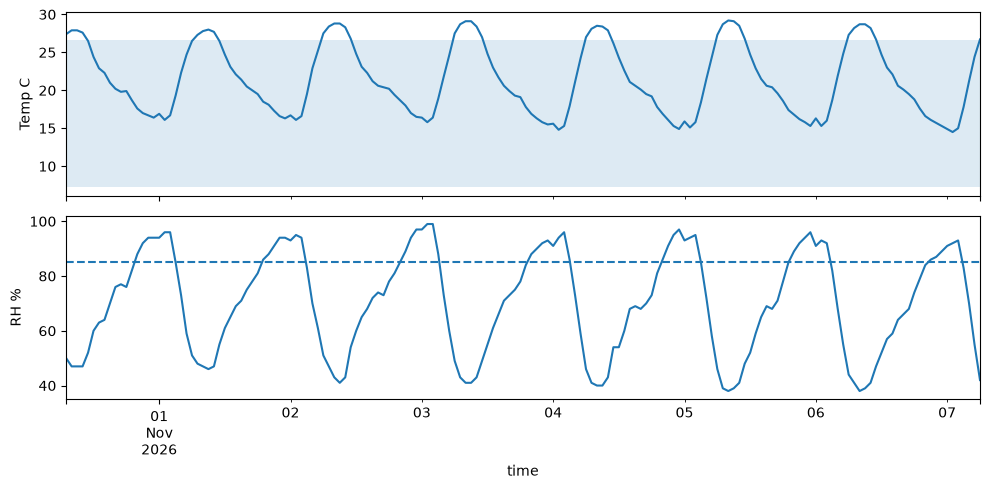

In [5]:
rh_ok = df.rh_pct >= rr.RH_MIN
temp_ok = df.temp_c.between(rr.TEMP_MIN, rr.TEMP_MAX)
print('RH >= 85%  :', int(rh_ok.sum()), 'h (need', rr.RH_HOURS_REQUIRED, ')')
print('7.2-26.6 C :', int(temp_ok.sum()), 'h (need', rr.TEMP_HOURS_REQUIRED, ')')
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
df.temp_c.plot(ax=ax[0]); ax[0].axhspan(rr.TEMP_MIN, rr.TEMP_MAX, alpha=.15); ax[0].set_ylabel('Temp C')
df.rh_pct.plot(ax=ax[1]); ax[1].axhline(rr.RH_MIN, ls='--'); ax[1].set_ylabel('RH %')
plt.tight_layout()

## 4. What-if: change a setting and see the level change
Useful when you calibrate against real data later.

In [6]:
rr.MODERATE_FRACTION = 0.6   # prototype setting, not from the papers
print(rr.late_blight_jhulsacast(obs).risk_level)

moderate
